<a href="https://colab.research.google.com/github/Lourdes-Churacutipa/Repositorio-de-lourdes/blob/main/Lab9_5_GNN_Grafos_Peru.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Redes Neuronales en Grafos: la Red de Drenaje como Modelo
## Ciencia de Datos Ambientales – Aplicado al Perú

**Duración:** 90 minutos · **Entorno:** Google Colab (funciona en CPU; con *GPU T4* entrena más rápido)

Última práctica del bloque de *deep learning*. Cambiamos de cuenca: el **río Piura en la estación Puente Sánchez Cerro** (ciudad de Piura, CAMELS-PE `PE_201201`). Usaremos también las **cuatro estaciones aguas arriba** que tiene CAMELS-PE en la misma cuenca.

---

### ¿Qué estructura tienen los datos?

| Lab | Arquitectura | Estructura de los datos | Qué comparten los pesos |
|---|---|---|---|
| 9_1 | MLP | Tabla: filas independientes | — |
| 9_2 | CNN | **Rejilla** regular (imagen) | Vecinos en el espacio (filtro) |
| 9_3 | RNN / LSTM | **Secuencia** (tiempo) | Pasos de tiempo consecutivos |
| 9_4 | Transformer | Conjunto de tokens, todos con todos | Pares de tokens (atención) |
| **9_5** | **GNN** | **Grafo**: nodos unidos por aristas arbitrarias | **Nodos conectados por aristas** |

Una cuenca **no es una rejilla ni una secuencia**: es una **red de drenaje**. El agua de la subcuenca A llega a B y luego a C. Si un modelo conoce esa estructura, podría usar la lluvia de cada subcuenca en el lugar correcto. Una red neuronal en grafos (*Graph Neural Network*, **GNN**) recibe esa estructura como parte del modelo.

### Objetivos de aprendizaje

1. Definir un **grafo** (nodos, aristas, dirección) y representarlo con su **matriz de adyacencia**.
2. Construir el grafo de la red de drenaje del río Piura a partir de los metadatos de CAMELS-PE.
3. Explicar el **paso de mensajes** (*message passing*) y cuántas capas necesita una GNN para "ver" toda la cuenca.
4. Implementar en Keras un modelo **grafo + LSTM** y compararlo con una LSTM de una sola estación.
5. Evaluar con honestidad si la estructura del grafo **realmente** aporta: experimentos de control (*ablation*), varias semillas y comparación con la literatura.

In [3]:
# Instalar lo necesario si el entorno no lo trae (en Colab normalmente ya está todo)
import importlib.util, subprocess, sys

for paquete, pip_nombre in [('tensorflow', 'tensorflow'), ('networkx', 'networkx'), ('gdown', 'gdown'),
                            ('geopandas', 'geopandas'), ('contextily', 'contextily')]:
    if importlib.util.find_spec(paquete) is None:
        print(f'Instalando {pip_nombre}...')
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pip_nombre])

import tensorflow as tf
print(f'TensorFlow {tf.__version__} | GPU: {len(tf.config.list_physical_devices("GPU")) > 0}')

TensorFlow 2.21.0 | GPU: True


In [4]:
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from tensorflow import keras
from tensorflow.keras import layers, ops

np.random.seed(42)
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

# 1. ¿Qué es un grafo?

Un **grafo** $G = (V, E)$ es un conjunto de **nodos** (vértices) $V$ unidos por **aristas** (enlaces) $E$.

| Concepto | Definición | En una red de drenaje |
|---|---|---|
| **Nodo** | Una entidad | Una estación hidrométrica y su subcuenca |
| **Arista** | Una relación entre dos nodos | "El agua de A fluye hacia B" |
| **Dirigido** | La arista tiene sentido: $A \to B \neq B \to A$ | El agua solo baja |
| **Atributos del nodo** | Vector de datos de cada nodo | Lluvia, radiación y área de la subcuenca |
| **Vecindario** | Nodos conectados a uno dado | Subcuencas que le entregan agua |

Una red de drenaje es un **árbol dirigido**: cada nodo tiene **una sola** salida aguas abajo, puede recibir **varios** afluentes y no hay ciclos. Hay grafos en todo el curso: estaciones meteorológicas vecinas, la red de monitoreo de calidad del aire de Lima, corredores de fauna entre áreas naturales protegidas o tuberías de una red de agua potable.

## 1.1 La red de estaciones del río Piura en CAMELS-PE

CAMELS-PE indica, para cada estación, qué cuencas están **anidadas** (una dentro de otra):

- `nested_group_id`: la estación de cierre del grupo, la más aguas abajo.
- `downstream_gauge_id`: la estación **inmediatamente aguas abajo**. Con esta columna construimos las aristas.

Subimos a Colab el archivo de atributos, los polígonos de las cuencas y las series diarias de las cinco estaciones.

In [5]:
# Archivos compartidos en Google Drive (ID o enlace completo; ~1.2 MB cada serie)
import re, gdown                                    # gdown viene preinstalado en Google Colab

ARCHIVOS = {
    'camels_pe_atributos.csv': '1tVbnC0athzvfe_Ht1GyjfDcg-KUSrzWZ',
    'PE_201201.csv':           '1AYV_Jj7KjcgDaVB6XXWlg7cAe2oO1ZtC',   # Puente Sánchez Cerro (objetivo)
    'PE_47E0522C.csv':         '1Kck2BtsGE8WJEoOpM36TDaFsAURK4zy2',   # Tambogrande
    'PE_47E0415A.csv':         '1n6NDcw1QgmRrx3DvlHDuS25RH4M6hGzJ',   # Puente Nacara
    'PE_47E074C0.csv':         '19pUZMq_TGa6xH3_w6hw7xKVOIsnMknWc',   # Hacienda Barrios
    'PE_47E08444.csv':         '1YnhoyrYy9b7sYYMhe3uQwsNiJ_0lZxbK',   # San Pedro
    'camels_pe_catchments.gpkg': '1-1N6mQbaMXKliMEtYwc19WIBWV4OInTX',                 # polígonos de las cuencas (~3.5 MB)
}

for archivo, fuente in ARCHIVOS.items():
    if not os.path.exists(archivo):
        if fuente.startswith('PEGAR'):
            raise ValueError(f'Falta el enlace de Google Drive de {archivo}')
        enlace = re.search(r'(?:id=|/d/)([\w-]{20,})', fuente)          # acepta un enlace de Drive o el ID solo
        gdown.download(id=enlace.group(1) if enlace else fuente, output=archivo, quiet=True)
print('Archivos listos:', sorted(f for f in os.listdir('.') if f.endswith('.csv')))

Archivos listos: ['PE_201201.csv', 'PE_47E0415A.csv', 'PE_47E0522C.csv', 'PE_47E074C0.csv', 'PE_47E08444.csv', 'camels_pe_atributos.csv']


In [6]:
OBJETIVO = 'PE_201201'                            # Puente Sánchez Cerro
atributos = pd.read_csv('camels_pe_atributos.csv')
red = atributos[atributos['nested_group_id'] == OBJETIVO].set_index('gauge_id')
red[['gauge_name', 'gauge_elev', 'area', 'downstream_gauge_id', 'gauge_record_start', 'gauge_record_end',
     'gauge_perc_obs']].sort_values('area')

,gauge_name,gauge_elev,area,downstream_gauge_id,gauge_record_start,gauge_record_end,gauge_perc_obs
gauge_id,,,,,,,
PE_47E08444,San Pedro,236,157.585,PE_47E0415A,2020-09-01,2025-12-31,10.67
PE_47E074C0,Hacienda Barrios,293,423.872,PE_47E0415A,2015-01-19,2025-12-31,20.27
PE_47E0415A,Puente Nacara,85,4641.436,PE_47E0522C,2021-03-03,2025-07-01,3.86
PE_47E0522C,Tambogrande,59,6392.086,PE_201201,2014-12-21,2025-04-12,10.91
PE_201201,Puente Sanchez Cerro,32,7507.306,NONE,1997-03-01,2023-05-22,29.68


Hay **cinco estaciones**. Para el modelo las ordenamos **de cabecera a salida** (orden topológico): un nodo siempre aparece antes que el nodo al que drena.

## 1.2 Mapa de ubicación: del territorio al grafo

Antes de abstraer, veamos la cuenca real. CAMELS-PE trae el polígono de la cuenca **total** de cada estación, y la de Tambogrande contiene a la de Puente Nacara. Para que cada nodo represente un territorio **distinto**, recortamos cada cuenca restándole las de aguas arriba. Así obtenemos las **subcuencas incrementales** (intercuencas), que serán los nodos del grafo.

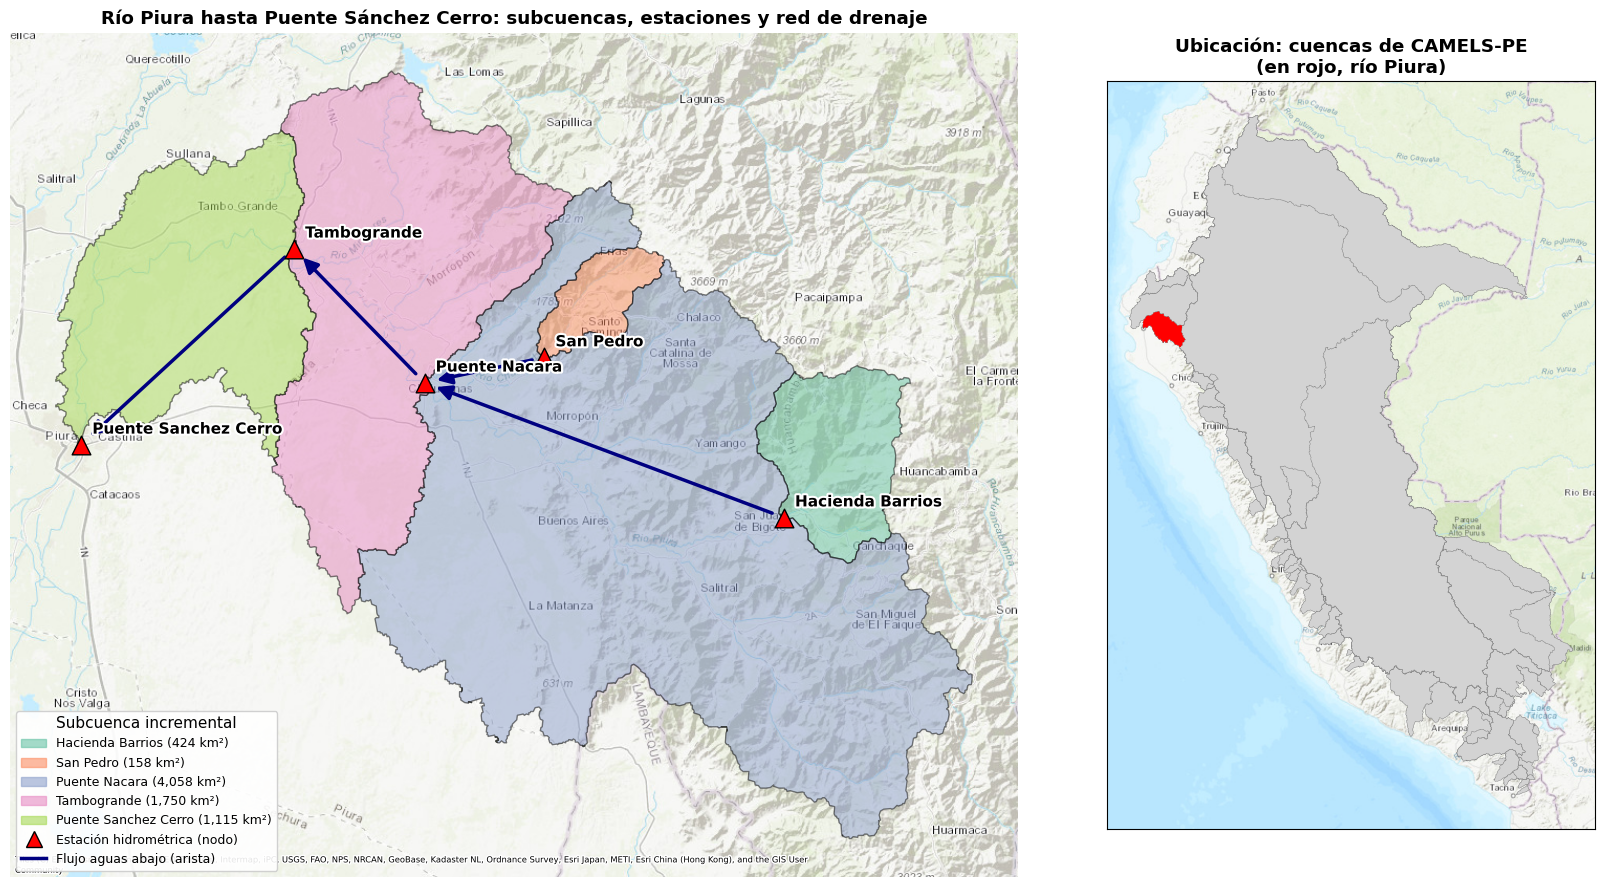

In [7]:
import geopandas as gpd
import shapely
import matplotlib.patches as mpatches
import matplotlib.patheffects as pe

ORDEN = ['PE_47E074C0', 'PE_47E08444', 'PE_47E0415A', 'PE_47E0522C', 'PE_201201']   # cabecera → salida
NOMBRES = [red.loc[g, 'gauge_name'] for g in ORDEN]
N = len(ORDEN)
indice = {g: i for i, g in enumerate(ORDEN)}

cuencas = gpd.read_file('camels_pe_catchments.gpkg')          # polígonos de las 136 cuencas de CAMELS-PE
poligono = cuencas.set_index('gauge_id').geometry

# Subcuenca incremental = cuenca de la estación MENOS las cuencas de las estaciones inmediatamente aguas arriba
incrementales = []
for g in ORDEN:
    arriba = red.index[red['downstream_gauge_id'] == g].tolist()
    geom = poligono[g]
    if arriba:
        geom = geom.difference(shapely.union_all([poligono[a] for a in arriba]))
    incrementales.append(geom)
subcuencas = gpd.GeoDataFrame({'nombre': NOMBRES}, geometry=incrementales, crs=cuencas.crs).to_crs(3857)
estaciones = gpd.GeoSeries(gpd.points_from_xy(red.loc[ORDEN, 'gauge_lon'], red.loc[ORDEN, 'gauge_lat']),
                           crs=4326).to_crs(3857)
xy = np.column_stack([estaciones.x, estaciones.y])
COLORES = plt.cm.Set2(np.arange(N))

fig, (ax, ax_ub) = plt.subplots(1, 2, figsize=(17, 9), gridspec_kw={'width_ratios': [2.4, 1]})
subcuencas.plot(ax=ax, color=COLORES, alpha=0.5, edgecolor='k', linewidth=1)
for i, j in zip(*np.nonzero([[red.loc[a, 'downstream_gauge_id'] == b for b in ORDEN] for a in ORDEN])):
    ax.annotate('', xy=xy[j], xytext=xy[i], zorder=4,
                arrowprops=dict(arrowstyle='-|>', color='navy', lw=2.5, mutation_scale=22, shrinkA=9, shrinkB=9))
ax.scatter(*xy.T, marker='^', s=180, color='red', edgecolor='k', zorder=5)
for k, nombre in enumerate(NOMBRES):
    ax.annotate(nombre, xy[k], xytext=(8, 8), textcoords='offset points', fontsize=11, fontweight='bold', zorder=6,
                path_effects=[pe.withStroke(linewidth=3, foreground='white')])
try:
    import contextily as cx
    cx.add_basemap(ax, source=cx.providers.Esri.WorldTopoMap, attribution_size=6)
except Exception as error:                                    # sin internet o sin contextily: mapa sin fondo
    print('Mapa base no disponible:', error)
ax.set_axis_off()
leyenda = [mpatches.Patch(color=COLORES[k], alpha=0.6, label=f'{NOMBRES[k]} ({area:,.0f} km²)')
           for k, area in enumerate(subcuencas.to_crs(32717).area / 1e6)]
leyenda += [plt.Line2D([], [], marker='^', ls='', color='red', mec='k', ms=11, label='Estación hidrométrica (nodo)'),
            plt.Line2D([], [], color='navy', lw=2.5, label='Flujo aguas abajo (arista)')]
ax.legend(handles=leyenda, title='Subcuenca incremental', loc='lower left', fontsize=9, framealpha=0.9)
ax.set_title('Río Piura hasta Puente Sánchez Cerro: subcuencas, estaciones y red de drenaje', fontweight='bold')

# Ubicación: todas las cuencas de CAMELS-PE y la del río Piura
todas = cuencas.to_crs(3857)
todas.plot(ax=ax_ub, color='lightgray', edgecolor='gray', linewidth=0.3)
todas[todas['gauge_id'] == OBJETIVO].plot(ax=ax_ub, color='red')
try:
    cx.add_basemap(ax_ub, source=cx.providers.Esri.WorldTopoMap, attribution=False)
except Exception:
    pass
ax_ub.set_xticks([]); ax_ub.set_yticks([]); ax_ub.set_xlabel(''); ax_ub.set_ylabel('')
ax_ub.set_title('Ubicación: cuencas de CAMELS-PE\n(en rojo, río Piura)', fontweight='bold')
plt.tight_layout(); plt.show()

**Del mapa al grafo:** cada color es un **nodo** y cada flecha es una **arista**. Para la GNN solo importa **quién drena a quién**: la forma, la distancia y la posición exacta de cada subcuenca no entran en la matriz de adyacencia. Por eso el grafo es una **abstracción** del territorio. Pierde geometría, pero conserva la topología. La geometría puede volver como **atributos** de los nodos (área, altitud, pendiente) o de las aristas (longitud del cauce, tiempo de viaje).

Puente Nacara drena la mayor parte de la cuenca (~4 060 km², el 54 %), incluido el sector de Morropón que se ve en el mapa. Puente Sánchez Cerro, en la ciudad de Piura, suma solo 1 115 km² propios.

## 1.3 La matriz de adyacencia

La forma estándar de guardar un grafo para hacer cálculos es la **matriz de adyacencia** $A$ de tamaño $N \times N$:

$$A_{ij} = \begin{cases} 1 & \text{si el nodo } i \text{ drena directamente hacia el nodo } j \\ 0 & \text{en otro caso} \end{cases}$$

- La **fila** $i$ dice hacia dónde va el agua de $i$. En un árbol de drenaje tiene **un solo 1**, salvo la salida, que no tiene ninguno.
- La **columna** $j$ dice quién le entrega agua a $j$. Puede tener varios 1 (confluencia).
- Como el grafo es dirigido, $A$ **no es simétrica**. En un grafo no dirigido, como "estaciones a menos de 50 km", sí lo sería.

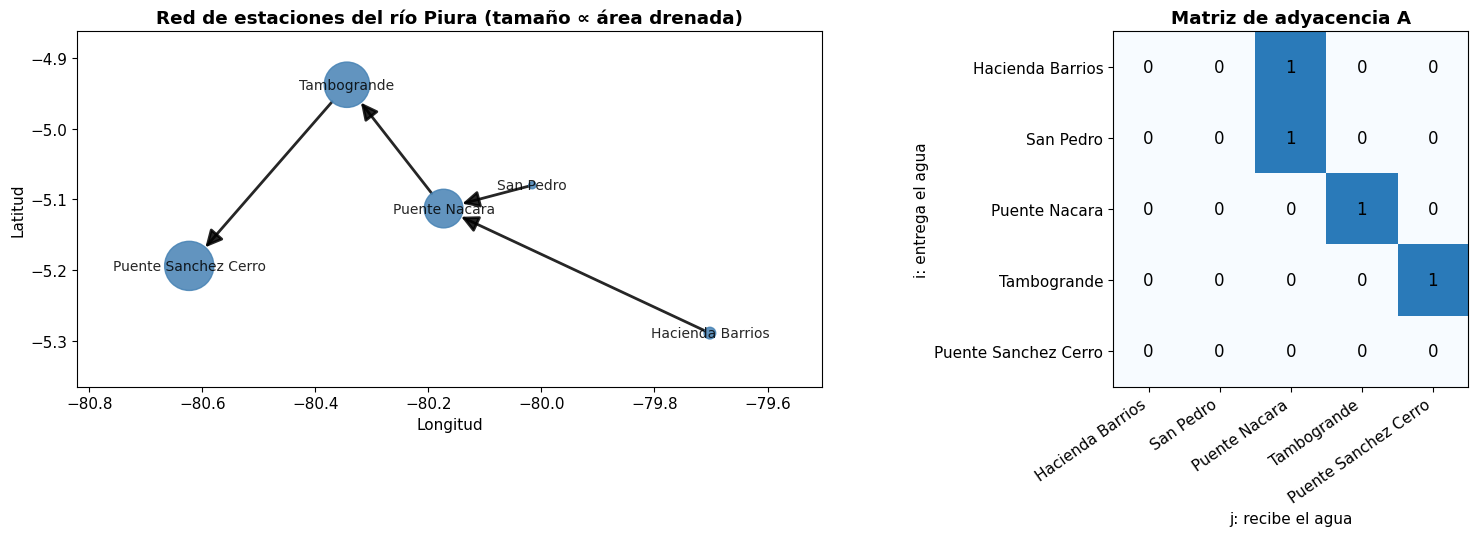

Afluentes que recibe cada nodo (suma de columnas): {'Hacienda Barrios': 0, 'San Pedro': 0, 'Puente Nacara': 2, 'Tambogrande': 1, 'Puente Sanchez Cerro': 1}
Salidas de cada nodo (suma de filas):             {'Hacienda Barrios': 1, 'San Pedro': 1, 'Puente Nacara': 1, 'Tambogrande': 1, 'Puente Sanchez Cerro': 0}


In [8]:
A = np.zeros((N, N), dtype='float32')
for g in ORDEN:
    abajo = red.loc[g, 'downstream_gauge_id']
    if abajo in indice:
        A[indice[g], indice[abajo]] = 1           # g drena hacia 'abajo'

grafo = nx.DiGraph()
for i, j in zip(*np.nonzero(A)):
    grafo.add_edge(NOMBRES[i], NOMBRES[j])

fig, ejes = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={'width_ratios': [1.3, 1]})
posicion = {NOMBRES[i]: (red.loc[g, 'gauge_lon'], red.loc[g, 'gauge_lat']) for i, g in enumerate(ORDEN)}
tamano = [red.loc[g, 'area'] / 6 for g in ORDEN]
nx.draw_networkx(grafo, pos=posicion, ax=ejes[0], nodelist=NOMBRES, node_size=tamano, node_color='steelblue',
                 alpha=0.85, arrowsize=25, font_size=10, edge_color='k', width=2)
ejes[0].set_title('Red de estaciones del río Piura (tamaño ∝ área drenada)', fontweight='bold')
ejes[0].set_xlabel('Longitud'); ejes[0].set_ylabel('Latitud'); ejes[0].tick_params(left=True, bottom=True, labelleft=True, labelbottom=True)
ejes[0].margins(0.15)

ejes[1].imshow(A, cmap='Blues', vmin=0, vmax=1.4)
for i in range(N):
    for j in range(N):
        ejes[1].text(j, i, int(A[i, j]), ha='center', va='center', fontsize=12)
ejes[1].set_xticks(range(N)); ejes[1].set_xticklabels(NOMBRES, rotation=35, ha='right')
ejes[1].set_yticks(range(N)); ejes[1].set_yticklabels(NOMBRES)
ejes[1].set_xlabel('j: recibe el agua'); ejes[1].set_ylabel('i: entrega el agua')
ejes[1].set_title('Matriz de adyacencia A', fontweight='bold')
plt.tight_layout(); plt.show()

print('Afluentes que recibe cada nodo (suma de columnas):', {n: int(v) for n, v in zip(NOMBRES, A.sum(0))})
print('Salidas de cada nodo (suma de filas):            ', {n: int(v) for n, v in zip(NOMBRES, A.sum(1))})

**Lectura de la red:** Hacienda Barrios (cabecera, ~1 800 msnm de altitud media) y San Pedro confluyen en **Puente Nacara**, que drena a **Tambogrande** y este a **Puente Sánchez Cerro**, en la ciudad de Piura.

## 1.4 Potencias de $A$: caminos y acumulación de flujo

Multiplicar matrices de adyacencia **recorre el grafo**:

- $(A^2)_{ij} = 1$ si hay un camino de **2 aristas** de $i$ a $j$; en general, $(A^k)_{ij}$ cuenta los caminos de $k$ aristas.
- En un árbol de drenaje, la suma $I + A + A^2 + \dots$ dice **quién está aguas arriba de quién**. Como no hay ciclos, la serie es finita y vale $(I - A)^{-1}$.

Comprobación hidrológica: el área drenada en cada estación debe ser el área **propia** de su subcuenca más el área drenada por todas las estaciones de aguas arriba. Si $a$ es el vector de áreas **incrementales** (solo la parte de la subcuenca entre una estación y las de aguas arriba):

$$\text{área acumulada} = (I - A^T)^{-1}\, a$$

                      área incremental (km²)  (I - Aᵀ)⁻¹ · a (km²)  \
Hacienda Barrios                       424.0                 424.0   
San Pedro                              158.0                 158.0   
Puente Nacara                         4060.0                4641.0   
Tambogrande                           1751.0                6392.0   
Puente Sanchez Cerro                  1115.0                7507.0   

                      área en CAMELS-PE (km²)  
Hacienda Barrios                        424.0  
San Pedro                               158.0  
Puente Nacara                          4641.0  
Tambogrande                            6392.0  
Puente Sanchez Cerro                   7507.0  


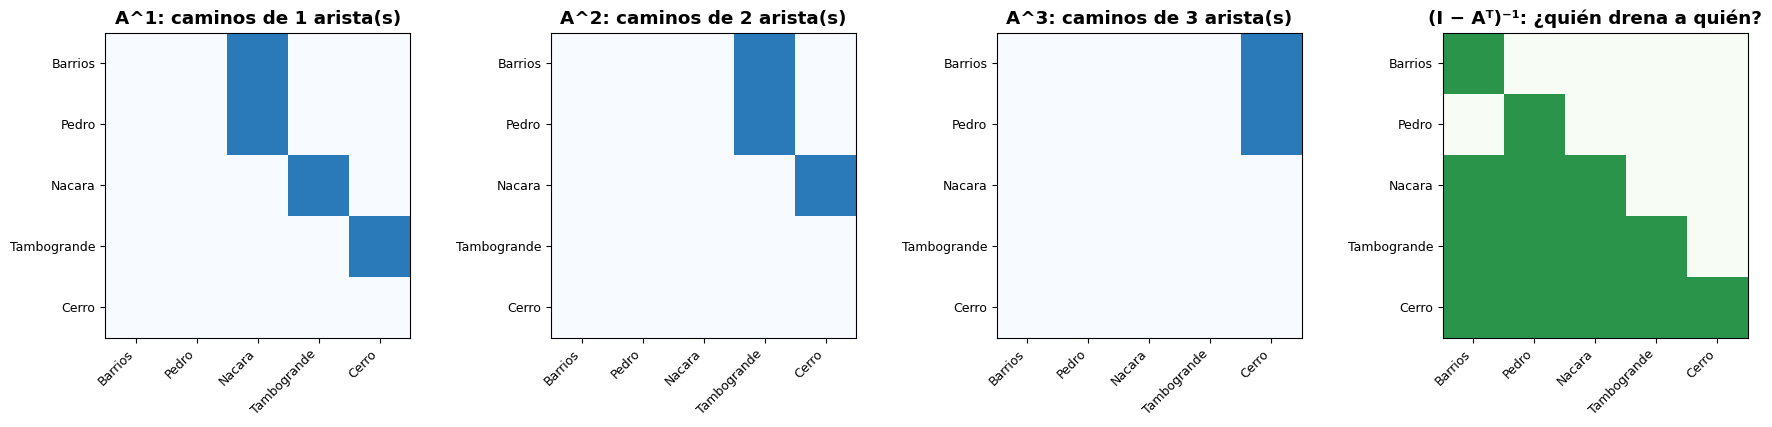

A⁴ es cero: el camino más largo de la red tiene 3 aristas. True


In [9]:
area = red.loc[ORDEN, 'area'].values                   # área total drenada en cada estación
area_inc = area - A.T @ area                           # restamos el área de las estaciones inmediatamente aguas arriba
acumulacion = np.linalg.inv(np.eye(N) - A.T)           # (I - Aᵀ)⁻¹: 1 si j está aguas arriba de i (o es i)

print(pd.DataFrame({'área incremental (km²)': area_inc.round(0),
                    '(I - Aᵀ)⁻¹ · a (km²)': (acumulacion @ area_inc).round(0),
                    'área en CAMELS-PE (km²)': area.round(0)}, index=NOMBRES))

fig, ejes = plt.subplots(1, 4, figsize=(18, 4.2))
for k, ax in enumerate(ejes[:3], start=1):
    ax.imshow(np.linalg.matrix_power(A, k), cmap='Blues', vmin=0, vmax=1.4)
    ax.set_title(f'A^{k}: caminos de {k} arista(s)', fontweight='bold')
ejes[3].imshow(acumulacion, cmap='Greens', vmin=0, vmax=1.4)
ejes[3].set_title('(I − Aᵀ)⁻¹: ¿quién drena a quién?', fontweight='bold')
for ax in ejes:
    ax.set_xticks(range(N)); ax.set_xticklabels([n.split()[-1] for n in NOMBRES], rotation=45, ha='right', fontsize=9)
    ax.set_yticks(range(N)); ax.set_yticklabels([n.split()[-1] for n in NOMBRES], fontsize=9)
plt.tight_layout(); plt.show()
print('A⁴ es cero: el camino más largo de la red tiene 3 aristas.', np.linalg.matrix_power(A, 4).sum() == 0)

El área reconstruida con $(I - A^T)^{-1}$ coincide con la de CAMELS-PE: la matriz describe bien la red. Además, $A^4 = 0$, así que la información de la cabecera necesita **3 saltos** para llegar a la salida. Este número define cuántas capas necesita la GNN.

# 2. Paso de mensajes: cómo "piensa" una GNN

Una GNN actualiza el vector de cada nodo en rondas. En cada ronda (una **capa**), cada nodo:

1. **Recibe mensajes** de sus vecinos. Aquí: de las subcuencas inmediatamente aguas arriba.
2. **Agrega** los mensajes con una operación que no depende del orden (suma, promedio o máximo).
3. **Actualiza** su propio vector combinando lo que tenía con lo que recibió.

$$h_i^{(k+1)} = \sigma\Big( W_{\text{propio}}\, h_i^{(k)} \;+\; W_{\text{vecinos}} \sum_{j \,\in\, \text{aguas arriba}(i)} h_j^{(k)} \Big)$$

En forma matricial, la suma de mensajes de todos los nodos es simplemente $A^T H$. Este es el esquema general de **paso de mensajes** (Gilmer et al., 2017). La *Graph Convolutional Network* (Kipf y Welling, 2017) es un caso particular con una normalización por grado.

**Ideas clave:**

- **Pesos compartidos:** $W_{\text{propio}}$ y $W_{\text{vecinos}}$ son **los mismos para todos los nodos**, igual que el filtro de una CNN se comparte en toda la imagen. Por eso el modelo sirve para grafos de cualquier tamaño.
- **Campo receptivo:** después de $k$ capas, cada nodo conoce a sus vecinos a $k$ saltos de distancia. Con nuestra red, la salida necesita **3 capas** para "ver" la cabecera.
- **Analogía hidrológica:** el paso de mensajes se parece al **tránsito de caudales** (*routing*), donde cada tramo recibe lo que viene de aguas arriba y le suma su aporte local. La diferencia es que la GNN **aprende** qué transmitir y cómo combinarlo.

Veamos el mecanismo sin pesos: un "pulso" de lluvia en Hacienda Barrios viaja por el grafo con $h^{(k+1)} = A^T h^{(k)}$.

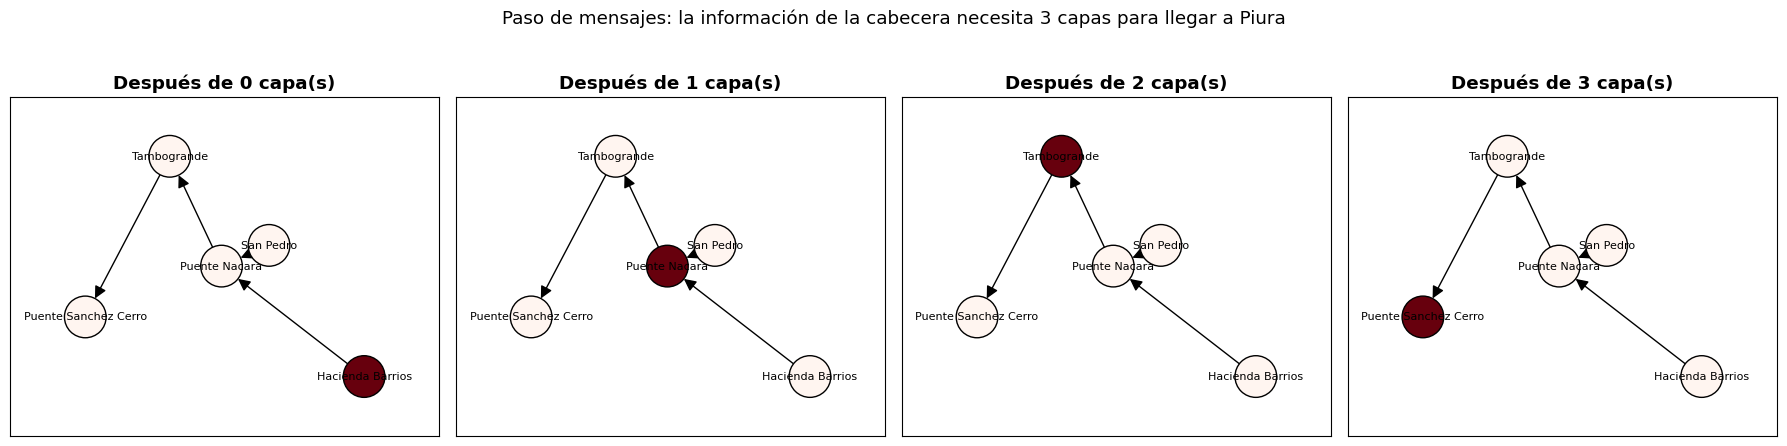

In [10]:
pulso = np.zeros(N); pulso[0] = 1.0                    # señal inicial solo en Hacienda Barrios
pasos = [pulso]
for _ in range(3):
    pasos.append(A.T @ pasos[-1])                      # cada nodo recibe la suma de sus vecinos aguas arriba

fig, ejes = plt.subplots(1, 4, figsize=(18, 4.3))
for k, (ax, h) in enumerate(zip(ejes, pasos)):
    nx.draw_networkx(grafo, pos=posicion, ax=ax, nodelist=NOMBRES, node_size=900,
                     node_color=h, cmap='Reds', vmin=0, vmax=1, edgecolors='k', arrowsize=18,
                     font_size=8, with_labels=True)
    ax.set_title(f'Después de {k} capa(s)', fontweight='bold'); ax.margins(0.2)
plt.suptitle('Paso de mensajes: la información de la cabecera necesita 3 capas para llegar a Piura', y=1.03)
plt.tight_layout(); plt.show()

Ahora una capa "de verdad", con pesos y activación, programada en NumPy. Cada nodo tiene un vector de 2 números y la capa lo transforma a 3:

In [11]:
rng = np.random.default_rng(0)
H = rng.normal(size=(N, 2))                            # vector de cada nodo (N nodos × 2 atributos)
W_propio = rng.normal(size=(2, 3))
W_vecinos = rng.normal(size=(2, 3))

def capa_mensajes(H, A, W_propio, W_vecinos):
    mensajes = A.T @ H                                 # 1-2. recibir y SUMAR lo que llega de aguas arriba
    return np.maximum(H @ W_propio + mensajes @ W_vecinos, 0)   # 3. actualizar (ReLU)

H1 = capa_mensajes(H, A, W_propio, W_vecinos)
print('Entrada H:', H.shape, '→ salida de la capa:', H1.shape)
print('Mensaje que recibe Puente Nacara = H[Barrios] + H[San Pedro]:', (A.T @ H)[2].round(3), '=', (H[0] + H[1]).round(3))
print('Mensaje que recibe Hacienda Barrios (cabecera, sin afluentes):', (A.T @ H)[0])

Entrada H: (5, 2) → salida de la capa: (5, 3)
Mensaje que recibe Puente Nacara = H[Barrios] + H[San Pedro]: [ 0.766 -0.027] = [ 0.766 -0.027]
Mensaje que recibe Hacienda Barrios (cabecera, sin afluentes): [0. 0.]


# 3. Datos: el río Piura en CAMELS-PE

## 3.1 ¿Qué información hay en cada estación?

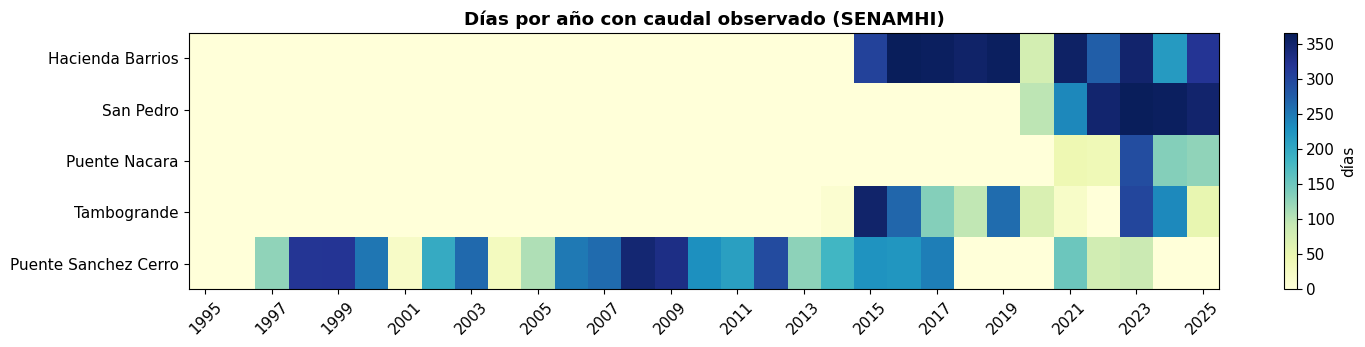

In [12]:
series = {g: pd.read_csv(f'{g}.csv', parse_dates=['date'], index_col='date') for g in ORDEN}

disponibilidad = pd.DataFrame({n: series[g]['flow_obs'].notna().groupby(series[g].index.year).sum()
                               for n, g in zip(NOMBRES, ORDEN)}).loc[1995:2025]
fig, ax = plt.subplots(figsize=(15, 3.6))
im = ax.imshow(disponibilidad.T, aspect='auto', cmap='YlGnBu', vmin=0, vmax=366)
ax.set_yticks(range(N)); ax.set_yticklabels(NOMBRES)
ax.set_xticks(range(0, len(disponibilidad), 2)); ax.set_xticklabels(disponibilidad.index[::2], rotation=45)
ax.set_title('Días por año con caudal observado (SENAMHI)', fontweight='bold')
plt.colorbar(im, ax=ax, label='días'); plt.tight_layout(); plt.show()

**Una limitación importante:** solo Puente Sánchez Cerro tiene caudal observado desde 1997. Las estaciones de aguas arriba empiezan entre **2015 y 2021**. Si queremos entrenar con 1998–2010, **no podemos usar el caudal observado aguas arriba como entrada**.

Lo que sí existe para **todas las subcuencas y todos los días** desde 1981 es la **meteorología**. Por eso, en este lab, el nodo del grafo es la **subcuenca** con su propio forzante meteorológico, no el caudal de la estación. Es la tarea de **simulación lluvia–escorrentía** (A1 del Lab 9_3): con la meteorología de los últimos 180 días, estimar el caudal de hoy en Piura.

## 3.2 Del forzante acumulado al forzante de cada subcuenca

CAMELS-PE da la lluvia **promedio de toda el área drenada** por cada estación. Así, la lluvia de Tambogrande ya incluye la de Hacienda Barrios. Para que cada nodo represente **solo su subcuenca** (la *intercuenca*), deshacemos el promedio ponderado por área:

$$P^{\text{inc}}_i = \frac{P_i\, A_i - \sum_{j \to i} P_j\, A_j}{A_i - \sum_{j \to i} A_j}$$

donde $A_i$ es el área drenada en la estación $i$ y la suma recorre las estaciones inmediatamente aguas arriba ($j \to i$). En forma matricial, la suma vuelve a ser $A^T$. Por diferencias de malla pueden salir valores ligeramente negativos de lluvia, que se truncan a 0.

**Variables:** `prec` (PISCOp), `srad` y `vprp` (ERA5-Land). En este lab **no usamos las temperaturas de PISCOt**: terminan en 2020, y sin ellas el periodo de prueba puede llegar a 2023 e incluir los dos eventos extremos recientes de Piura, **El Niño Costero 2017** y el **ciclón Yaku de marzo de 2023**. La presión de vapor y la radiación de ERA5-Land ya llevan buena parte de la señal térmica.

Error máximo al reconstruir la lluvia de la cuenca: 0.0009 mm/d


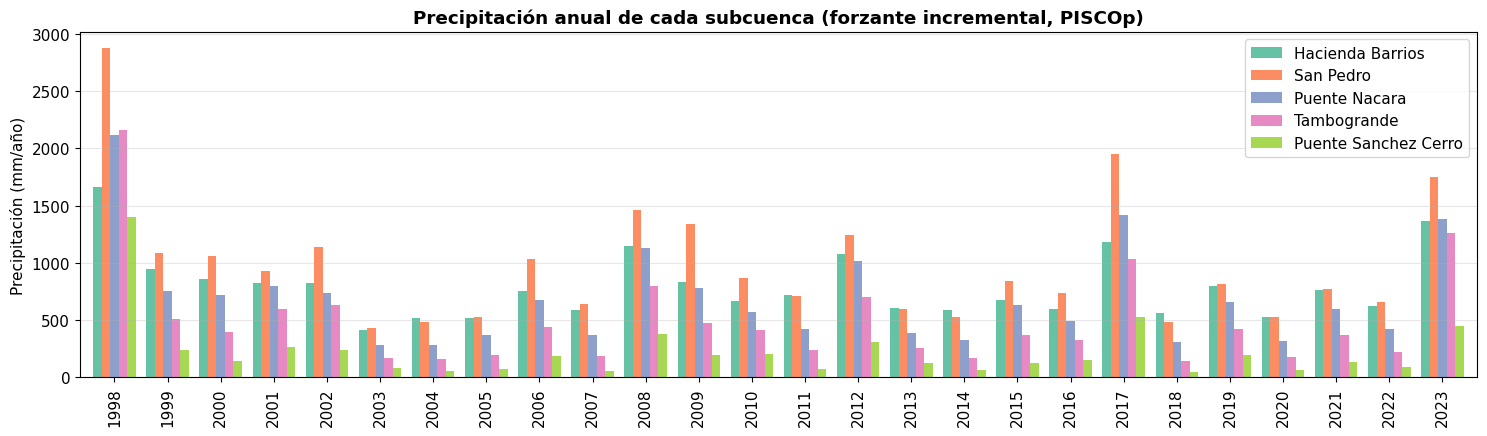

In [13]:
VARS = ['prec', 'srad', 'vprp']
df = series[OBJETIVO].loc['1996-01-01':'2023-12-31']   # 2 años extra para llenar las primeras ventanas
fechas = df.index

X_acum = np.stack([series[g].loc[fechas, VARS].values for g in ORDEN], axis=1).astype('float32')  # (días, nodos, variables)
peso = X_acum * area[None, :, None]                                                # variable × área
X_inc = (peso - np.einsum('ji,tjf->tif', A, peso)) / area_inc[None, :, None]       # deshacer el promedio por área
X_inc[..., 0] = np.maximum(X_inc[..., 0], 0)                                       # lluvia no negativa

# Verificación: el promedio ponderado de las subcuencas debe reproducir la lluvia de toda la cuenca
reconstruida = (X_inc[:, :, 0] * area_inc).sum(1) / area[-1]
print(f'Error máximo al reconstruir la lluvia de la cuenca: {np.abs(reconstruida - X_acum[:, -1, 0]).max():.4f} mm/d')

lluvia_anual = pd.DataFrame(X_inc[:, :, 0], index=fechas, columns=NOMBRES).loc['1998':'2023'].resample('YE').sum()
fig, ax = plt.subplots(figsize=(15, 4.5))
lluvia_anual.index = lluvia_anual.index.year
lluvia_anual.plot.bar(ax=ax, width=0.8, color=COLORES)       # mismos colores que el mapa
ax.set_xlabel(''); ax.set_ylabel('Precipitación (mm/año)'); ax.grid(axis='y', alpha=0.3)
ax.set_title('Precipitación anual de cada subcuenca (forzante incremental, PISCOp)', fontweight='bold')
plt.tight_layout(); plt.show()

Cada subcuenca tiene su propio régimen: en años **El Niño** (1998, 2017, 2023) llueve mucho más, con distinta intensidad en cada una. Esta información espacial se **pierde** cuando se promedia toda la cuenca, como hace la LSTM de una sola estación.

## 3.3 Preparación (igual que en el Lab 9_3)

- **Periodos:** entrenamiento **1998–2010** (incluye El Niño 1997–98), validación **2011–2015** (*early stopping*) y prueba **2016–2023** (Niño Costero 2017 y ciclón Yaku 2023).
- **Normalización** con media y desviación del entrenamiento; **logaritmo** del caudal.
- **Objetivo:** el caudal observado en Puente Sánchez Cerro, solo los días con dato.
- **Referencia física:** el modelo hidrológico **PISCO-ARNOVIC** (`flow_sim`).

In [14]:
entrena = fechas <= '2010-12-31'

def normalizar(X):
    return (X - X[entrena].mean(0)) / X[entrena].std(0)

X_salida_n = normalizar(X_acum[:, -1, :])               # meteorología de TODA la cuenca (promedio)
X_inc_n = normalizar(X_inc)                             # meteorología de cada subcuenca

q_obs = df['flow_obs'].values
q_log = np.log(q_obs + 0.05)
q_media, q_desv = np.nanmean(q_log[entrena]), np.nanstd(q_log[entrena])
q_n = (q_log - q_media) / q_desv

def a_caudal(v):
    return np.maximum(np.exp(np.asarray(v) * q_desv + q_media) - 0.05, 0)

def nse(obs, sim):
    return 1 - np.sum((obs - sim) ** 2) / np.sum((obs - obs.mean()) ** 2)

def kge(obs, sim):
    r = np.corrcoef(obs, sim)[0, 1]
    return 1 - np.sqrt((r - 1) ** 2 + (sim.std() / obs.std() - 1) ** 2 + (sim.mean() / obs.mean() - 1) ** 2)

VENTANA = 180
t = np.arange(VENTANA - 1, len(df))
t = t[~np.isnan(q_obs[t]) & (fechas[t] >= '1998-01-01')]  # solo días con caudal observado
fechas_t = fechas[t]
periodos = {'entrena': fechas_t <= '2010-12-31',
            'valida': (fechas_t > '2010-12-31') & (fechas_t <= '2015-12-31'),
            'prueba': fechas_t >= '2016-01-01'}
y = q_n[t].astype('float32')

def ventanas(X):
    return np.stack([X[i - VENTANA + 1:i + 1] for i in t]).astype('float32')

X_1est = ventanas(X_salida_n)                                     # (muestras, 180, 3)
X_grafo = ventanas(X_inc_n).transpose(0, 2, 1, 3)                 # (muestras, 5 nodos, 180, 3)
area_n = (np.log(area_inc) - np.log(area_inc).mean()) / np.log(area_inc).std()
X_grafo = np.concatenate([X_grafo, np.broadcast_to(area_n[None, :, None, None], X_grafo.shape[:3] + (1,))],
                         axis=-1).astype('float32')               # + área de la subcuenca (atributo estático)
X_concat = X_grafo[..., :3].transpose(0, 2, 1, 3).reshape(len(t), VENTANA, -1)   # (muestras, 180, 15)

print('LSTM una estación :', X_1est.shape, '→ (muestras, días, variables)')
print('GNN               :', X_grafo.shape, '→ (muestras, nodos, días, variables + área)')
print('LSTM concatenada  :', X_concat.shape, '→ (muestras, días, 5 subcuencas × 3 variables)')
print({k: int(v.sum()) for k, v in periodos.items()})

LSTM una estación : (4751, 180, 3) → (muestras, días, variables)
GNN               : (4751, 5, 180, 4) → (muestras, nodos, días, variables + área)
LSTM concatenada  : (4751, 180, 15) → (muestras, días, 5 subcuencas × 3 variables)
{'entrena': 2926, 'valida': 1040, 'prueba': 785}


# 4. Práctica: LSTM de una estación vs. grafo + LSTM

Comparamos cuatro modelos entrenados con los mismos datos y los mismos días objetivo:

| Modelo | Entrada | ¿Sabe dónde llueve? | ¿Conoce la red? |
|---|---|---|---|
| **A. LSTM 1 estación** | Meteorología promedio de toda la cuenca | No | No |
| **B. LSTM concatenada** | Las 5 subcuencas como 15 columnas | Sí | No |
| **C. GNN (grafo + LSTM)** | Las 5 subcuencas como nodos + matriz $A$ | Sí | **Sí** |
| **D. GNN sin mensajes ($k=0$)** | Igual que C, pero lee solo el nodo de salida | Solo su subcuenca | No |

B y D son **experimentos de control** (*ablation*). Si C supera a A, ¿es por la **estructura del grafo** o solo porque recibe **más información**? B tiene la misma información que C pero sin grafo. D muestra qué pasa si la salida **no recibe** mensajes de aguas arriba.

## 4.1 Arquitectura del modelo grafo + LSTM

```
 Entrada: (5 nodos × 180 días × 4 variables)
        │
 [1] LSTM COMPARTIDA ── la misma LSTM resume los 180 días de CADA subcuenca
        │                  → un vector h_i de 32 números por nodo ("estado" de la subcuenca)
        │
 [2] Paso de mensajes × 3 ── h_i ← ReLU(W_propio·h_i + W_vecinos·Σ h_aguas_arriba)
        │                       (3 capas = el camino más largo de la red)
        │
 [3] Lectura en el nodo de salida (Puente Sánchez Cerro) → Dense(1): caudal
```

Este diseño **espacio-temporal** es habitual en hidrología con GNN: primero un modelo temporal por nodo, luego un modelo espacial sobre el grafo (p. ej., Sun et al., 2021). Como siempre en este curso, la capa de mensajes la escribimos **nosotros**, sin librerías especializadas (en proyectos grandes se usan PyTorch Geometric, DGL o Spektral).

In [15]:
class PasoMensajes(layers.Layer):
    # Una capa de GNN: cada nodo combina su vector con la SUMA de los vectores de aguas arriba
    def __init__(self, A, unidades, **kwargs):
        super().__init__(**kwargs)
        self.A = np.asarray(A, dtype='float32')                   # matriz de adyacencia fija (N × N)
        self.propio = layers.Dense(unidades)                      # W_propio (con sesgo)
        self.vecinos = layers.Dense(unidades, use_bias=False)     # W_vecinos

    def call(self, h):                                            # h: (lote, N, unidades)
        mensajes = ops.einsum('ji,bjf->bif', self.A, h)           # Aᵀ·H para cada muestra del lote
        return ops.relu(self.propio(h) + self.vecinos(mensajes))

def construir_gnn(n_capas=3, unidades=32):
    entrada = keras.Input(shape=X_grafo.shape[1:])                         # (5, 180, 4)
    h = layers.TimeDistributed(layers.LSTM(unidades), name='lstm_compartida')(entrada)  # [1] (lote, 5, 32)
    for k in range(n_capas):
        h = PasoMensajes(A, unidades, name=f'mensajes_{k + 1}')(h)         # [2]
    salida = h[:, -1, :]                                                   # [3] nodo de salida (último en ORDEN)
    salida = layers.Dense(1)(layers.Dropout(0.2)(salida))
    return keras.Model(entrada, salida, name=f'GNN_k{n_capas}')

def construir_lstm(forma, unidades=32):
    return keras.Sequential([keras.Input(shape=forma), layers.LSTM(unidades),
                             layers.Dropout(0.2), layers.Dense(1)], name='LSTM')

construir_gnn().summary()

Model: "GNN_k3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 5, 180, 4)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_compartida                 │ (None, 5, 32)          │         4,736 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mensajes_1 (PasoMensajes)       │ (None, 5, 32)          │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mensajes_2 (PasoMensajes)       │ (None, 5, 32)          │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mensajes_3 (PasoMensajes)       │ (None, 5, 32)          │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ get_item (GetItem)              │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,009 (43.00 KB)

 Trainable params: 11,009 (43.00 KB)

 Non-trainable params: 0 (0.00 B)

Fíjate en la capa `TimeDistributed(LSTM)`: aplica **la misma LSTM** a cada uno de los 5 nodos. La GNN tiene muy pocos parámetros más que la LSTM simple. Lo nuevo no son los parámetros, sino **cómo se combinan** los nodos.

## 4.2 Entrenamiento con varias semillas

Con pocos datos, el resultado de una red neuronal **depende de la semilla aleatoria** (pesos iniciales y orden de los lotes). Para no sacar conclusiones de la suerte, entrenamos cada modelo **3 veces**. Reportamos la media y la desviación, y además el **ensamble** (promedio de las 3 predicciones).

⏱️ En CPU tarda ~5–8 minutos en total; en GPU 19 mins.

In [16]:
def entrenar(modelo, X, epocas=60):
    modelo.compile(optimizer=keras.optimizers.Adam(1e-3), loss='mse')
    e, v = periodos['entrena'], periodos['valida']
    modelo.fit(X[e], y[e], epochs=epocas, batch_size=128, validation_data=(X[v], y[v]), verbose=0,
               callbacks=[keras.callbacks.EarlyStopping(patience=8, restore_best_weights=True)])
    return modelo

EXPERIMENTOS = {
    'A. LSTM 1 estación':         (lambda: construir_lstm(X_1est.shape[1:]), X_1est),
    'B. LSTM concatenada':        (lambda: construir_lstm(X_concat.shape[1:]), X_concat),
    'C. GNN (grafo + LSTM)':      (lambda: construir_gnn(n_capas=3), X_grafo),
    'D. GNN sin mensajes (k=0)':  (lambda: construir_gnn(n_capas=0), X_grafo),
}
SEMILLAS = [0, 1, 2]
pred = {}                                    # pred[modelo][periodo] = lista de predicciones (una por semilla)
modelos = {}                                 # modelos entrenados, para interpretarlos después
for nombre, (constructor, X) in EXPERIMENTOS.items():
    t0 = time.time()
    pred[nombre] = {'valida': [], 'prueba': []}
    modelos[nombre] = []
    for semilla in SEMILLAS:
        keras.utils.set_random_seed(semilla)
        modelo = entrenar(constructor(), X)
        modelos[nombre].append(modelo)
        for per in ['valida', 'prueba']:
            pred[nombre][per].append(a_caudal(modelo.predict(X[periodos[per]], verbose=0).ravel()))
    print(f'{nombre:<28s} {modelo.count_params():>6d} parámetros   {time.time() - t0:5.0f} s')

A. LSTM 1 estación             4641 parámetros      32 s
B. LSTM concatenada            6177 parámetros      25 s
C. GNN (grafo + LSTM)         11009 parámetros      81 s
D. GNN sin mensajes (k=0)      4769 parámetros      57 s


In [17]:
filas = {}
for per in ['valida', 'prueba']:
    obs = q_obs[t][periodos[per]]
    filas[('PISCO-ARNOVIC', per)] = (nse(obs, df['flow_sim'].values[t][periodos[per]]), 0,
                                      kge(obs, df['flow_sim'].values[t][periodos[per]]), np.nan)
    filas[('PISCO-ARNOVIC', per)] = (filas[('PISCO-ARNOVIC', per)][0], np.nan, filas[('PISCO-ARNOVIC', per)][2], np.nan)
    for nombre in EXPERIMENTOS:
        nses = [nse(obs, p) for p in pred[nombre][per]]
        ensamble = np.mean(pred[nombre][per], axis=0)
        filas[(nombre, per)] = (np.mean(nses), np.std(nses), kge(obs, ensamble), nse(obs, ensamble))

tabla = pd.DataFrame(filas, index=['NSE medio', 'NSE desv.', 'KGE ensamble', 'NSE ensamble']).T.unstack()
tabla = tabla.swaplevel(axis=1)[['valida', 'prueba']].round(3)
tabla

valida                                      \
                          NSE medio NSE desv. KGE ensamble NSE ensamble   
A. LSTM 1 estación            0.759     0.042        0.785        0.774   
B. LSTM concatenada           0.781     0.010        0.819        0.805   
C. GNN (grafo + LSTM)         0.748     0.069        0.871        0.776   
D. GNN sin mensajes (k=0)     0.684     0.069        0.621        0.724   
PISCO-ARNOVIC                 0.522       NaN        0.703          NaN   

                             prueba                                      
                          NSE medio NSE desv. KGE ensamble NSE ensamble  
A. LSTM 1 estación            0.809     0.003        0.822        0.821  
B. LSTM concatenada           0.801     0.016        0.776        0.816  
C. GNN (grafo + LSTM)         0.852     0.022        0.878        0.877  
D. GNN sin mensajes (k=0)     0.669     0.125        0.604        0.715  
PISCO-ARNOVIC                 0.624       NaN        0.799          NaN

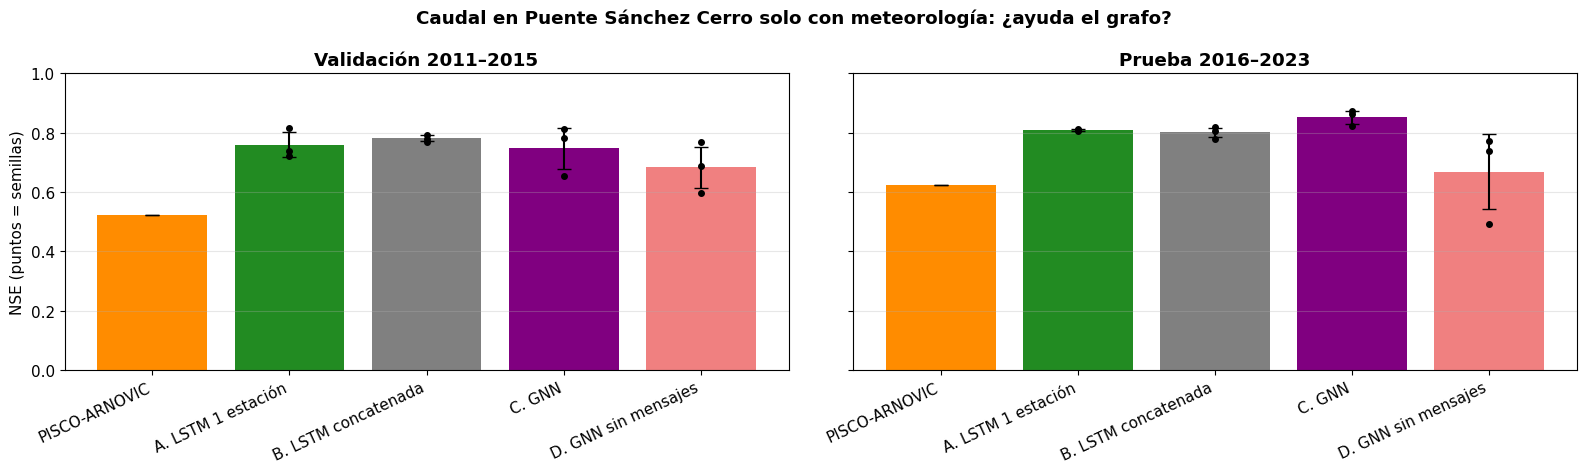

In [18]:
fig, ejes = plt.subplots(1, 2, figsize=(16, 4.8), sharey=True)
colores = ['darkorange', 'forestgreen', 'gray', 'purple', 'lightcoral']
nombres = ['PISCO-ARNOVIC'] + list(EXPERIMENTOS)
for ax, per, titulo in [(ejes[0], 'valida', 'Validación 2011–2015'), (ejes[1], 'prueba', 'Prueba 2016–2023')]:
    medias = [tabla.loc[n, (per, 'NSE medio')] for n in nombres]
    desv = [tabla.loc[n, (per, 'NSE desv.')] for n in nombres]
    ax.bar(range(len(nombres)), medias, yerr=np.nan_to_num(desv), capsize=5, color=colores)
    for k, n in enumerate(nombres[1:], start=1):              # cada semilla como un punto
        obs = q_obs[t][periodos[per]]
        ax.plot([k] * len(SEMILLAS), [nse(obs, p) for p in pred[n][per]], 'k.', ms=8)
    ax.set_xticks(range(len(nombres))); ax.set_xticklabels([n.split(' (')[0] for n in nombres], rotation=25, ha='right')
    ax.set_title(titulo, fontweight='bold'); ax.grid(axis='y', alpha=0.3); ax.set_ylim(0, 1)
ejes[0].set_ylabel('NSE (puntos = semillas)')
plt.suptitle('Caudal en Puente Sánchez Cerro solo con meteorología: ¿ayuda el grafo?', fontweight='bold')
plt.tight_layout(); plt.show()

## 4.3 Los eventos extremos: Niño Costero 2017 y ciclón Yaku 2023

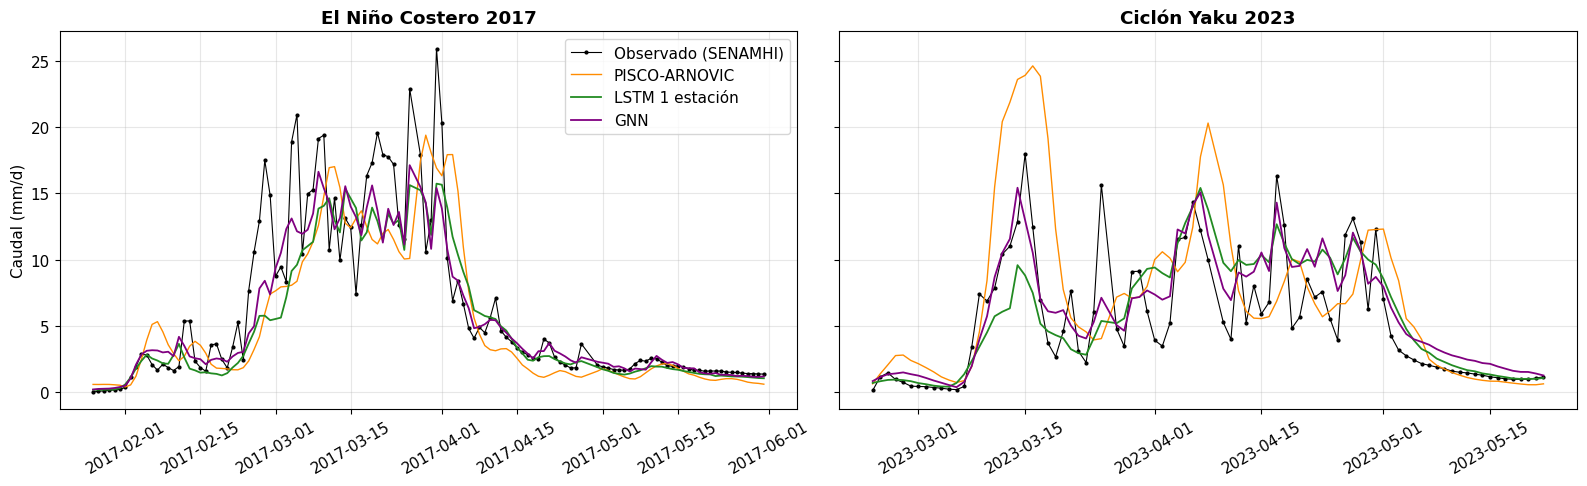

Días con caudal ≥ percentil 95 en la prueba: 40
  A. LSTM 1 estación       sesgo medio en esos días: -25%
  C. GNN (grafo + LSTM)    sesgo medio en esos días: -19%


In [19]:
p = periodos['prueba']
f = fechas_t[p]
obs_te = q_obs[t][p]
ens = {n: np.mean(pred[n]['prueba'], axis=0) for n in ['A. LSTM 1 estación', 'C. GNN (grafo + LSTM)']}

fig, ejes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
for ax, (ini, fin, titulo) in zip(ejes, [('2017-01-01', '2017-05-31', 'El Niño Costero 2017'),
                                         ('2023-01-01', '2023-05-31', 'Ciclón Yaku 2023')]):
    sel = (f >= ini) & (f <= fin)
    ax.plot(f[sel], obs_te[sel], 'k.-', ms=4, lw=0.8, label='Observado (SENAMHI)')
    ax.plot(f[sel], df['flow_sim'].values[t][p][sel], '-', color='darkorange', lw=1, label='PISCO-ARNOVIC')
    ax.plot(f[sel], ens['A. LSTM 1 estación'][sel], '-', color='forestgreen', lw=1.3, label='LSTM 1 estación')
    ax.plot(f[sel], ens['C. GNN (grafo + LSTM)'][sel], '-', color='purple', lw=1.3, label='GNN')
    ax.set_title(titulo, fontweight='bold'); ax.grid(alpha=0.3); ax.tick_params(axis='x', rotation=30)
ejes[0].set_ylabel('Caudal (mm/d)'); ejes[0].legend()
plt.tight_layout(); plt.show()

pico = obs_te >= np.quantile(obs_te, 0.95)
print(f"Días con caudal ≥ percentil 95 en la prueba: {pico.sum()}")
for n, v in ens.items():
    print(f"  {n:<24s} sesgo medio en esos días: {np.mean(v[pico] - obs_te[pico]) / np.mean(obs_te[pico]):+.0%}")

### ¿Qué observamos?

En nuestra ejecución (CPU, semillas 0–2; en Colab los valores cambian un poco con la versión de TensorFlow y con la GPU):

- **Todas las redes con meteorología de la cuenca completa superan a PISCO-ARNOVIC en NSE** (prueba: ~0.81–0.85 frente a 0.62). En **KGE**, en cambio, ARNOVIC (0.80) queda cerca de la LSTM (0.82): el NSE castiga sobre todo los errores en los picos.
- **En la prueba 2016–2023, la GNN es el mejor modelo:** NSE 0.85 ± 0.02 frente a 0.81 de la LSTM de una estación (0.88 frente a 0.82 con el ensamble). En los días de crecida (≥ P95) subestima menos (−19 % frente a −25 %), y en el primer pico del ciclón Yaku (mediados de marzo de 2023) se acerca más al observado.
- **Pero en la validación 2011–2015 no gana:** NSE 0.71 ± 0.14, con una semilla que cae a 0.52. Allí el mejor es la LSTM concatenada (0.78). La GNN es **más inestable**: tiene más capas y depende más de la inicialización.
- **B ≈ A:** darle a la LSTM las 5 subcuencas como columnas **no mejora** a la LSTM con el promedio de la cuenca. Más información sin estructura no basta.
- **D es mucho peor que C** (0.62 frente a 0.85): sin paso de mensajes, el nodo de salida solo conoce su intercuenca (1 115 km², el 15 % de la cuenca). Esto confirma que las capas de mensajes **sí transportan** la información de aguas arriba hasta Piura.

**Conclusión honesta:** la evidencia es **favorable pero no concluyente**. La GNN gana claramente en un periodo con dos eventos extremos, pero no en el otro, y la diferencia con la LSTM es del mismo orden que la variación entre semillas en la validación. Para afirmar que la estructura del grafo ayuda, habría que probar más semillas, más cuencas y validación cruzada temporal.

> **Con más semillas la ventaja se achica.** En una prueba aparte con **5 semillas** (0–4), la GNN obtuvo NSE 0.83 ± 0.02 en la prueba frente a 0.81 ± 0.00 de la LSTM, y 0.72 frente a 0.75 en la validación. Tres semillas son pocas: una sola (aquí, la semilla 0, con 0.46 en validación) mueve mucho la media.

## 4.4 ¿Qué subcuenca pesa más? Interpretación por oclusión

Una forma sencilla de interpretar un modelo es **apagar una entrada y ver qué pasa** (*oclusión*). Para cada nodo ponemos su lluvia en **0 mm/d** durante toda la ventana, dejamos el resto igual y medimos cuánto baja el **volumen** de caudal simulado en Piura (prueba 2016–2023, promedio de las semillas).

Si la GNN aprendió algo hidrológicamente razonable, el efecto de cada subcuenca debería parecerse a **su aporte de lluvia** (área × lluvia media). La relación no será exacta, porque la escorrentía no es lineal. La GNN sin mensajes (D), en cambio, **no puede** reaccionar a la lluvia de aguas arriba.

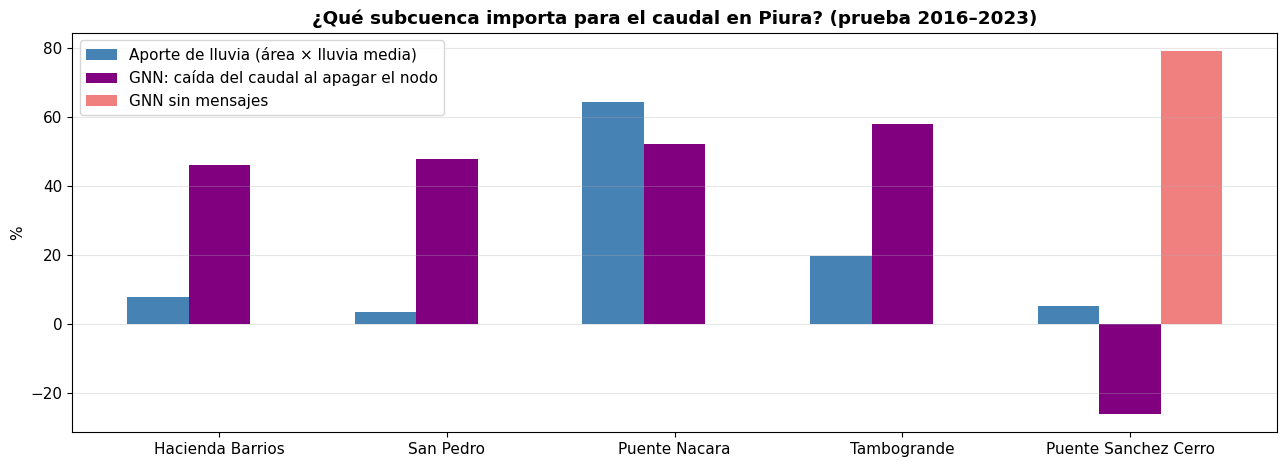

                      aporte de lluvia (%)  GNN (%)  GNN sin mensajes (%)
Hacienda Barrios                       7.7     46.1                   0.0
San Pedro                              3.4     47.6                   0.0
Puente Nacara                         64.1     52.0                   0.0
Tambogrande                           19.6     57.9                   0.0
Puente Sanchez Cerro                   5.2    -26.2                  79.0


In [20]:
p = periodos['prueba']
media_prec = X_inc[entrena, :, 0].mean(0)
desv_prec = X_inc[entrena, :, 0].std(0)
cero = -media_prec / desv_prec                        # "0 mm/d" expresado en la escala normalizada

def volumen(nombre, X):
    return np.mean([a_caudal(m.predict(X, verbose=0).ravel()).sum() for m in modelos[nombre]])

efecto = {}
for nombre in ['C. GNN (grafo + LSTM)', 'D. GNN sin mensajes (k=0)']:
    base = volumen(nombre, X_grafo[p])
    efecto[nombre] = []
    for i in range(N):
        X_sin_lluvia = X_grafo[p].copy()
        X_sin_lluvia[:, i, :, 0] = cero[i]            # apagar la lluvia SOLO del nodo i
        efecto[nombre].append(100 * (1 - volumen(nombre, X_sin_lluvia) / base))

lluvia_volumen = X_inc[fechas >= '2016-01-01', :, 0].mean(0) * area_inc
aporte = 100 * lluvia_volumen / lluvia_volumen.sum()

fig, ax = plt.subplots(figsize=(13, 4.8))
ancho = 0.27
ax.bar(np.arange(N) - ancho, aporte, ancho, color='steelblue', label='Aporte de lluvia (área × lluvia media)')
ax.bar(np.arange(N), efecto['C. GNN (grafo + LSTM)'], ancho, color='purple', label='GNN: caída del caudal al apagar el nodo')
ax.bar(np.arange(N) + ancho, efecto['D. GNN sin mensajes (k=0)'], ancho, color='lightcoral', label='GNN sin mensajes')
ax.set_xticks(range(N)); ax.set_xticklabels(NOMBRES)
ax.set_ylabel('%'); ax.grid(axis='y', alpha=0.3); ax.legend()
ax.set_title('¿Qué subcuenca importa para el caudal en Piura? (prueba 2016–2023)', fontweight='bold')
plt.tight_layout(); plt.show()

print(pd.DataFrame({'aporte de lluvia (%)': aporte, 'GNN (%)': efecto['C. GNN (grafo + LSTM)'],
                    'GNN sin mensajes (%)': efecto['D. GNN sin mensajes (k=0)']}, index=NOMBRES).round(1))

### ¿Qué nos dice la oclusión?

- **La GNN sin mensajes (D)** solo reacciona a la lluvia de su propio nodo (efecto 0 % en todos los demás). Era lo esperado: confirma que, sin paso de mensajes, la salida es "ciega" aguas arriba.
- **La GNN (C) sí reacciona a todos los nodos de aguas arriba**: el paso de mensajes funciona. Pero **la magnitud no es hidrológica**:
  - Apagar **San Pedro**, que aporta ~3 % de la lluvia, reduce el caudal casi a la mitad. Lo mismo ocurre con Hacienda Barrios.
  - Los efectos suman mucho más de 100 %.
  - Apagar la lluvia del **propio nodo de salida *aumenta*** el caudal simulado.
- **¿Por qué?** La lluvia de las subcuencas vecinas está **muy correlacionada**: cuando llueve en la cabecera, suele llover en toda la cuenca. La GNN no aprendió "cuánta agua aporta cada subcuenca", sino a usar cada nodo como un **indicador** de que la cuenca entera está húmeda. Además, "lluvia 0 en un solo nodo mientras llueve en los demás" es una situación que el modelo **nunca vio** al entrenar (fuera de distribución), así que la oclusión también tiene límites.

**Lección:** un NSE alto **no garantiza** que el modelo represente bien el proceso físico. Es la misma conclusión de Kirschstein y Sun (2024): los pesos que aprende una GNN no coinciden necesariamente con la red física. Un modelo hidrológico como PISCO-ARNOVIC, con menor NSE, sí conserva la masa por construcción. Para acercar la GNN a la física habría que agregarle restricciones (p. ej., de balance de masa) o entrenar con caudales observados en los nodos intermedios.

# 5. Pensamiento crítico: ¿cuándo vale la pena un grafo?

## 5.1 Lo que dice la literatura

- **Sun et al. (2021)** aplicaron GNN a cientos de cuencas de CAMELS (EE. UU.) y encontraron que pueden aprender relaciones espacio-temporales entre cuencas.
- **Kirschstein y Sun (2024, ICML)** probaron GNN para pronosticar caudales en una red grande de estaciones europeas. Su resultado fue **negativo**: el modelo **no se benefició** de la topología del río, ni en la red completa ni en subgrafos pequeños, y los pesos de arista que aprendió no coincidían con la red física.

Una mejora en una cuenca y un periodo **no demuestra** que los grafos siempre ayuden. La pregunta correcta no es "¿la GNN es mejor?", sino "¿en qué condiciones la estructura aporta información que el modelo no podía obtener de otra forma?".

## 5.2 Limitaciones de este experimento

| Aspecto | Comentario |
|---|---|
| **Nodos sin caudal** | Los nodos llevan solo meteorología. El potencial real de una GNN aparece cuando los nodos de aguas arriba tienen **caudal observado** como entrada: la crecida que ya pasó por Tambogrande "avisa" a Piura. Aquí no fue posible porque esos registros empiezan en 2015 o después. |
| **Pocos nodos** | 5 nodos y un grafo casi lineal. Las GNN muestran su fuerza con cientos o miles de nodos y muchas confluencias. |
| **Agua que no está en el grafo** | Parte del caudal del bajo Piura no viene de la lluvia de la cuenca: el **canal de derivación Daniel Escobar** trae agua del río Chira (reservorio de Poechos) y la descarga en la caída de Curumuy, en el bajo Piura. Además, la **presa derivadora Los Ejidos**, unos 7 km aguas arriba de la ciudad, capta agua para riego. Ningún forzante meteorológico representa estos aportes y extracciones. Un grafo completo debería incluir el **trasvase como un nodo más**. |
| **Forzante incremental** | Al restar promedios de áreas grandes se amplifican los errores de PISCOp en las subcuencas pequeñas. |
| **Variabilidad** | Con 3 semillas y ~800 días de prueba, diferencias de 0.02–0.04 en NSE están dentro del ruido. |
| **Regla de oro** | Compara siempre contra controles: aquí, la LSTM concatenada (B) y la GNN sin mensajes (D). |

## 5.3 ¿Dónde más se usan grafos en ciencias ambientales?

| Aplicación | Nodos | Aristas |
|---|---|---|
| Pronóstico de caudales | Estaciones hidrométricas | Tramos de río (aguas abajo) |
| Calidad del aire en Lima (Lab 3) | Estaciones de monitoreo | Distancia o dirección del viento |
| Pronóstico del tiempo global (GraphCast, Lam et al., 2023) | Puntos de una malla sobre la esfera | Vecindad en varias escalas |
| Ecología del paisaje | Parches de hábitat / ANP | Corredores de dispersión |
| Redes de agua potable | Nodos de demanda | Tuberías |

---
## 🔬 Ejercicios

1. **Profundidad del grafo.** Entrena la GNN con `n_capas = 1, 2, 3, 4`. ¿Cómo cambia el NSE? Relaciónalo con el camino más largo de la red ($A^4 = 0$). ¿Qué esperas con 4 capas?
2. **Grafo equivocado.** Reemplaza `A` por un grafo **completamente conectado** (`np.ones((N, N)) - np.eye(N)`) y por la **red invertida** (`A.T`, el agua "sube"). ¿Empeora el modelo? ¿Qué te dice eso sobre si la GNN usa realmente la topología?
3. **Agregación.** Cambia la **suma** de mensajes por el **promedio** (divide entre el número de afluentes, con cuidado en las cabeceras). ¿Cambia algo en esta red? ¿En qué tipo de red importaría más?
4. **Pesos de las aristas.** Agrega a la capa `PasoMensajes` un peso aprendible por arista (un `add_weight` de tamaño N × N multiplicado por `A`). Después de entrenar, ¿qué afluente "pesa" más? ¿Coincide con su área o su lluvia?
5. **Conexiones residuales.** Cambia la salida de `PasoMensajes` por `h + ReLU(...)`, como en los bloques del Transformer (Lab 9_4). ¿Se vuelve más estable entre semillas? (En nuestra prueba con 5 semillas **no mejoró**: NSE 0.78 en la prueba. ¿Por qué podría ser?)
6. **Usar el caudal de aguas arriba.** Para 2015–2023, Tambogrande y Hacienda Barrios sí tienen caudal observado. Diseña un experimento de **pronóstico a 1–3 días** (como la A2 del Lab 9_3) en el que esos caudales sean atributos de los nodos. Discute qué periodos de entrenamiento y prueba podrías usar con tan pocos años.
7. **Temperaturas.** Repite todo con `VARS = ['prec', 'tmean', 'srad', 'vprp']` y la prueba en 2016–2020. ¿Cambia la conclusión? ¿Cuántos días de prueba te quedan?
8. **Otra cuenca.** Usa `nested_group_size` en `camels_pe_atributos.csv` para encontrar la red anidada **más grande** de CAMELS-PE. ¿Cuántos nodos y confluencias tiene? Dibuja su grafo y su matriz de adyacencia.
9. **Debate.** El SENAMHI opera estaciones en una red de ríos. ¿Qué tendría que cambiar en la red de monitoreo (densidad, continuidad de registros, transmisión en tiempo real) para que un modelo en grafos fuera útil en la alerta temprana de crecidas en Piura?

---
## Resumen

| Concepto | Conclusión clave |
|---|---|
| Grafo | Nodos + aristas; una red de drenaje es un árbol **dirigido** |
| Matriz de adyacencia $A$ | $A_{ij} = 1$ si $i$ drena hacia $j$; no es simétrica en grafos dirigidos |
| Potencias de $A$ | $A^k$ cuenta caminos de $k$ aristas; $(I-A^T)^{-1}$ acumula áreas y flujos |
| Paso de mensajes | Recibir → agregar → actualizar; los pesos se comparten entre todos los nodos |
| Campo receptivo | $k$ capas = información de $k$ saltos; aquí bastan 3 |
| Grafo + LSTM | LSTM compartida en el tiempo + paso de mensajes en el espacio |
| Forzante incremental | Cada nodo debe representar solo su subcuenca, no el área acumulada |
| Ablation | Separar el efecto de la **estructura** del efecto de la **cantidad de información** |
| Regla de oro | Una arquitectura más sofisticada debe superar a controles simples, con varias semillas y en más de un periodo |

### Deep Learning en el curso

| Lab | Generación | Datos | Aplicación peruana |
|---|---|---|---|
| 9_1 | MLP | Tabulares | Cobertura desde índices espectrales |
| 9_2 | CNN | Imágenes | Parches satelitales, deforestación |
| 9_3 | RNN / LSTM | Series de tiempo | Caudales del Majes, Titicaca |
| 9_4 | Transformer / Fundacional | Secuencias, cualquier modalidad | Pronóstico *zero-shot* de caudales |
| **9_5** | **GNN** | **Grafos** | **Red de drenaje del río Piura** |

## Lecturas recomendadas

- Gilmer, J., et al. (2017). Neural message passing for quantum chemistry. *ICML*.
- Kipf, T. N., & Welling, M. (2017). Semi-supervised classification with graph convolutional networks. *ICLR*.
- Battaglia, P. W., et al. (2018). Relational inductive biases, deep learning, and graph networks. *arXiv:1806.01261*.
- Kratzert, F., et al. (2018). Rainfall–runoff modelling using Long Short-Term Memory (LSTM) networks. *HESS*, 22, 6005–6022.
- Sun, A. Y., Jiang, P., Mudunuru, M. K., & Chen, X. (2021). Explore spatio-temporal learning of large sample hydrology using graph neural networks. *Water Resources Research*, 57(12), e2021WR030394.
- Kirschstein, N., & Sun, Y. (2024). The merit of river network topology for neural flood forecasting. *ICML*, PMLR 235. Código: github.com/nkirschi/neural-flood-forecasting
- Lam, R., et al. (2023). Learning skillful medium-range global weather forecasting. *Science*, 382, 1416–1421 (GraphCast).